# DZ13 – аналіз часу доставки у закладі «Чотири сири»

У цьому завданні досліджуємо час доставки піци (у хвилинах), який виміряв власник закладу «Чотири сири». На діаграмі видно такі значення часу доставки:

**16, 18, 19, 21, 22, 24, 25, 25, 29 (хвилин)**.

Потрібно:
1. Знайти **середнє значення** часу доставки.
2. Знайти **медіану**.
3. Знайти **моду**.
4. Побудувати **boxplot**.
5. Перевірити, чи є **викиди** у даних.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Дані з діаграми (час доставки в хвилинах)
data = [16, 18, 19, 21, 22, 24, 25, 25, 29]

df = pd.DataFrame({
    'delivery_time': data
})

df

,delivery_time
0,16
1,18
2,19
3,21
4,22
5,24
6,25
7,25
8,29


### Дослідження
- Імпортували бібліотеки **pandas**, **numpy**, **matplotlib.pyplot**.
- Створили список значень `data` з часами доставки (у хвилинах).
- На основі цього списку побудували `DataFrame` `df` з одним стовпчиком `delivery_time`.
- Виводимо таблицю, щоб переконатися, що всі значення внесені правильно.

In [2]:
mean_time = df['delivery_time'].mean()
median_time = df['delivery_time'].median()
mode_time = df['delivery_time'].mode()[0]

print(f'Середній час доставки: {mean_time:.1f} хв')
print(f'Медіана: {median_time:.1f} хв')
print(f'Мода: {mode_time:.1f} хв')

Середній час доставки: 22.1 хв
Медіана: 22.0 хв
Мода: 25.0 хв


### Дослідження
1. **Середнє значення** (арифметичне середнє) обчислюється за формулою:

> середнє значення  =  (сума всіх значень)  /  (кількість значень)

Підставляємо наші дані:

> середнє  =  (16 + 18 + 19 + 21 + 22 + 24 + 25 + 25 + 29) / 9  ≈  22.1 хв

Отже, **в середньому** замовлення доставляють приблизно за **22.1 хвилини**.

2. **Медіана** – це серединне значення у відсортованому ряду. Відсортований ряд:

> 16, 18, 19, 21, **22**, 24, 25, 25, 29

Середнє (5-те) значення дорівнює **22**, тому **медіана = 22 хв**.

3. **Мода** – це значення, яке зустрічається найчастіше. У нашому наборі даних число **25** зустрічається двічі, а всі інші – лише один раз, тому **мода = 25 хв**.

**Висновок:** типовий час доставки близький до 22 хв, а найчастіше спостерігається час 25 хв.

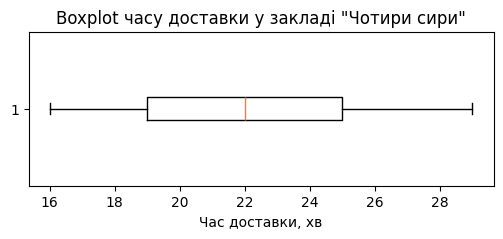

In [3]:
plt.figure(figsize=(6, 2))
plt.boxplot(df['delivery_time'], vert=False)
plt.xlabel('Час доставки, хв')
plt.title('Boxplot часу доставки у закладі "Чотири сири"')
plt.show()

### Дослідження
- Побудували **boxplot** (ящик з вусами) для часу доставки.
- Ящик показує діапазон від першого квартиля (**Q1**) до третього квартиля (**Q3**).
- Вертикальна лінія всередині ящика показує **медіану**.
- «Вуса» відображають мінімальне та максимальне значення без викидів.

За графіком видно, що основна частина значень знаходиться у проміжку приблизно від 19 до 25 хвилин.

In [4]:
q1 = df['delivery_time'].quantile(0.25)
q3 = df['delivery_time'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f'Q1 = {q1:.1f}')
print(f'Q3 = {q3:.1f}')
print(f'IQR = {iqr:.1f}')
print(f'Нижня межа(bound) = {lower_bound:.1f}')
print(f'Верхня межа(bound) = {upper_bound:.1f}')

outliers = df[(df['delivery_time'] < lower_bound) | (df['delivery_time'] > upper_bound)]
outliers

Q1 = 19.0
Q3 = 25.0
IQR = 6.0
Нижня межа(bound) = 10.0
Верхня межа(bound) = 34.0


,delivery_time


### Дослідження
Щоб знайти **викиди**, використовуємо правило **1.5 · IQR**.

1. Обчислюємо перший та третій квартилі:

> Q1 = 19 хв  
> Q3 = 25 хв

2. Обчислюємо міжквартильний розмах (**IQR**):

> IQR = Q3 − Q1 = 25 − 19 = 6 хв

3. Обчислюємо нижню та верхню межі для викидів:

> нижня межа  =  Q1 − 1.5 · IQR  =  19 − 1.5 · 6  =  19 − 9  =  10  
> верхня межа =  Q3 + 1.5 · IQR  =  25 + 1.5 · 6  =  25 + 9  =  34

Усі наші значення часу доставки лежать у діапазоні від **16** до **29** хвилин, тобто між 10 та 34. Це означає, що **жодне значення не виходить за межі** [10; 34], і тому у таблиці `outliers` немає жодного рядка.

**Висновок:** у даних **немає викидів**, усі часи доставки є досить типовими для цього закладу.

## Загальний підсумок
- **Середній час доставки** ≈ **22.1 хв**.
- **Медіана** = **22 хв** – половина замовлень доставляється швидше, а половина повільніше.
- **Мода** = **25 хв** – найчастіший час доставки.
- **Boxplot** показує, що основна маса значень знаходиться у проміжку приблизно від 19 до 25 хв.
- За правилом **1.5 · IQR** **викидів немає**, тобто немає аномально довгих або дуже коротких доставок.

**Загальний висновок:** доставка у закладі «Чотири сири» є доволі стабільною, без екстремальних затримок. Типовий час очікування замовлення – близько 22 хвилин.